[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jadg1/economic-networks-seminar/blob/main/labs/dean_reach.ipynb)

**Run it in Google Colab, with nothing to install:** click the badge, then run the setup cell below first. On your own computer the setup cell does nothing.

In [ ]:
# Setup for Google Colab: gets the repository's files and the two extra packages.
# On your own computer (with the econ-networks environment) this cell does nothing.
import os, sys
if "google.colab" in sys.modules:
    REPO = "jadg1/economic-networks-seminar"
    if not os.path.exists("/content/economic-networks-seminar"):
        !git clone -q --depth 1 https://github.com/{REPO}.git /content/economic-networks-seminar
    %cd /content/economic-networks-seminar/labs
    %pip install -q pyreadr pyvis
    print("Ready: running from the repository's labs folder.")

# Reaching the dean: a long chain of favours, or a post-it on the secretary's desk?

Economic Networks, Part 1 (with a link to Part 2)  

Each link has a probability that the ask actually gets passed on: the person  
you ask remembers, bothers, and mentions it to the next person. Edit the  
numbers in LINKS to match your own story.  

Two ways to think about it:  
1. One chosen route. The message only goes one way, so the chance it  
arrives is the PRODUCT of the probabilities along the route. The most  
reliable route is found with Dijkstra on -log(probability), because  
adding logs is the same as multiplying probabilities.  
2. Word of mouth. Everyone who hears about it has one chance to mention it  
to each of their contacts (the "independent cascade" model of spreading,  
Kempe, Kleinberg and Tardos, 2003). Several routes can work at once, so  
redundancy helps. Computed exactly, by checking every combination of  
which asks work and which don't.  

`Needs: pip install networkx matplotlib numpy`

## Setup: the people and the chance each ask gets passed on

In [1]:
%matplotlib inline

In [2]:
from itertools import product
from math import log, prod
import networkx as nx
import matplotlib.pyplot as plt

LINKS = {   # (person, person): probability the ask gets passed on
    ("You", "Classmate"): 0.95,
    ("You", "Professor"): 0.85,
    ("Classmate", "Professor"): 0.60,
    ("Professor", "Head of dept"): 0.80,
    ("Professor", "Secretary"): 0.50,      # a formal request that may get lost
    ("Head of dept", "Secretary"): 0.85,
    ("Head of dept", "Vice-dean"): 0.70,
    ("Vice-dean", "Dean"): 0.80,
    ("Secretary", "Dean"): 0.90,           # she runs his diary
    ("You", "Secretary"): 0.40,            # the post-it on her desk
}
START, TARGET = "You", "Dean"

POS = {"You": (0, 2), "Classmate": (0, 0.4), "Professor": (2, 2), "Head of dept": (4, 1.2),
       "Secretary": (6, 3), "Vice-dean": (6, -0.2), "Dean": (8, 1.6)}
INK, MUTED, LINE, BLUE, CORAL, GREEN = "#1B1F3B", "#8A8FA8", "#C9CCD8", "#2D6CF6", "#F2464F", "#12A873"


def build():
    G = nx.Graph()
    for (a, b), p in LINKS.items():
        G.add_edge(a, b, p=p, cost=-log(p))
    return G

## 1. One chosen route: multiply the probabilities

In [3]:
def route_probability(G, route):
    return prod(G[a][b]["p"] for a, b in zip(route, route[1:]))


def all_routes(G):
    routes = [(r, route_probability(G, r)) for r in nx.all_simple_paths(G, START, TARGET)]
    return sorted(routes, key=lambda x: -x[1])


def most_reliable_route(G):
    """Dijkstra on -log(p): the shortest path is the most reliable chain."""
    return nx.dijkstra_path(G, START, TARGET, weight="cost")

## 2. Word of mouth: every working link passes the message on

In [4]:
def chance_dean_hears(G, first_asks):
    """Exact probability the dean hears, if you make `first_asks` (your own links
    you use) and everyone who hears mentions it to all their contacts."""
    links = [(a, b) for a, b in G.edges() if START not in (a, b)]
    total = 0.0
    for works in product([True, False], repeat=len(links)):
        weight = prod(G[a][b]["p"] if w else 1 - G[a][b]["p"] for (a, b), w in zip(links, works))
        H = nx.Graph()
        H.add_nodes_from(G)
        H.add_edges_from(e for e, w in zip(links, works) if w)
        # your own asks: each works with its probability
        for mine in product([True, False], repeat=len(first_asks)):
            w2 = prod(G[START][f]["p"] if m else 1 - G[START][f]["p"] for f, m in zip(first_asks, mine))
            heard = {f for f, m in zip(first_asks, mine) if m}
            reached = set().union(*(nx.node_connected_component(H, f) for f in heard)) if heard else set()
            if TARGET in reached:
                total += weight * w2
    return total


STRATEGIES = {
    "Post-it to the secretary": ["Secretary"],
    "Ask your professor": ["Professor"],
    "Ask your classmate": ["Classmate"],
    "Post-it and ask your professor": ["Secretary", "Professor"],
    "Ask everyone you know": ["Classmate", "Professor", "Secretary"],
}

## 3. The telephone game: why long chains fail

In [5]:
def chain_decay(p=0.8, max_people=6):
    return [(k, p ** k) for k in range(1, max_people + 1)]

## Pictures

In [6]:
def draw_network(G, best, path=None):
    fig, ax = plt.subplots(figsize=(10, 4.8))
    best_links = {frozenset(e) for e in zip(best, best[1:])}
    for a, b, d in G.edges(data=True):
        (xa, ya), (xb, yb) = POS[a], POS[b]
        postit = {a, b} == {"You", "Secretary"}
        on_best = frozenset((a, b)) in best_links
        col = BLUE if on_best else (CORAL if postit else LINE)
        ax.plot([xa, xb], [ya, yb], color=col, lw=1 + 6 * d["p"], ls="--" if postit else "-",
                zorder=1, solid_capstyle="round")
        ax.text((xa + xb) / 2, (ya + yb) / 2, f"{d['p']:.0%}", ha="center", va="center", fontsize=9,
                color=INK, bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none"), zorder=3)
    for n, (x, y) in POS.items():
        ax.text(x, y, n, ha="center", va="center", fontsize=10, fontweight="bold", color="white",
                bbox=dict(boxstyle="round,pad=0.45", lw=0, fc=INK if n in (START, TARGET) else MUTED),
                zorder=4)
    ax.set_title(f"Best chain (blue) arrives {route_probability(G, best):.0%} of the time; "
                 f"the post-it (coral) {route_probability(G, ['You', 'Secretary', 'Dean']):.0%}",
                 loc="left", fontsize=11)
    ax.text(-0.4, -1.05, "Numbers: chance each ask gets passed on. Thicker line = more likely.",
            fontsize=9, color=MUTED)
    ax.set_xlim(-0.8, 8.8)
    ax.set_ylim(-1.2, 3.6)
    ax.axis("off")
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=160)
    return fig


def draw_strategies(results, path=None):
    fig, ax = plt.subplots(figsize=(8, 3.4))
    names = list(results)
    vals = [results[n] for n in names]
    best = max(vals)
    ax.barh(names[::-1], vals[::-1], color=[GREEN if v == best else (CORAL if "Post-it to" in n else MUTED)
                                            for n, v in zip(names[::-1], vals[::-1])])
    for i, v in enumerate(vals[::-1]):
        ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=9, color=INK)
    ax.set_xlim(0, 1.05)
    from matplotlib.ticker import PercentFormatter
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_xlabel("chance the dean hears about it (word of mouth)")
    ax.set_title("More routes, more chances: redundancy beats a single ask", loc="left", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=160)
    return fig


def draw_decay(p=0.8, path=None):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    pts = chain_decay(p)
    ax.plot([k for k, _ in pts], [v for _, v in pts], marker="o", color=BLUE, lw=2.2)
    for k, v in pts:
        ax.text(k, v + 0.04, f"{v:.0%}", ha="center", fontsize=9, color=INK)
    ax.set_xlabel("people in the chain")
    ax.set_ylabel("chance it arrives")
    ax.set_ylim(0, 1)
    from matplotlib.ticker import PercentFormatter
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(f"The telephone game: each person passes it on {p:.0%} of the time",
                 loc="left", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=160)
    return fig

## Run everything

1. One chosen route (multiply the probabilities):
     52%  You -> Professor -> Head of dept -> Secretary -> Dean
     38%  You -> Professor -> Secretary -> Dean
     38%  You -> Professor -> Head of dept -> Vice-dean -> Dean
     36%  You -> Secretary -> Dean
     35%  You -> Classmate -> Professor -> Head of dept -> Secretary -> Dean
     26%  You -> Classmate -> Professor -> Secretary -> Dean
     26%  You -> Classmate -> Professor -> Head of dept -> Vice-dean -> Dean
     20%  You -> Professor -> Secretary -> Head of dept -> Vice-dean -> Dean
     19%  You -> Secretary -> Head of dept -> Vice-dean -> Dean
     14%  You -> Classmate -> Professor -> Secretary -> Head of dept -> Vice-dean -> Dean
      9%  You -> Secretary -> Professor -> Head of dept -> Vice-dean -> Dean
   Dijkstra on -log(p) picks: You -> Professor -> Head of dept -> Secretary -> Dean (52%)

2. Word of mouth (everyone who hears passes it on):
     38%  Post-it to the secretary
     71%  Ask your professor
     48% 


Saved dean_fig1_routes.png, dean_fig2_strategies.png, dean_fig3_telephone.png


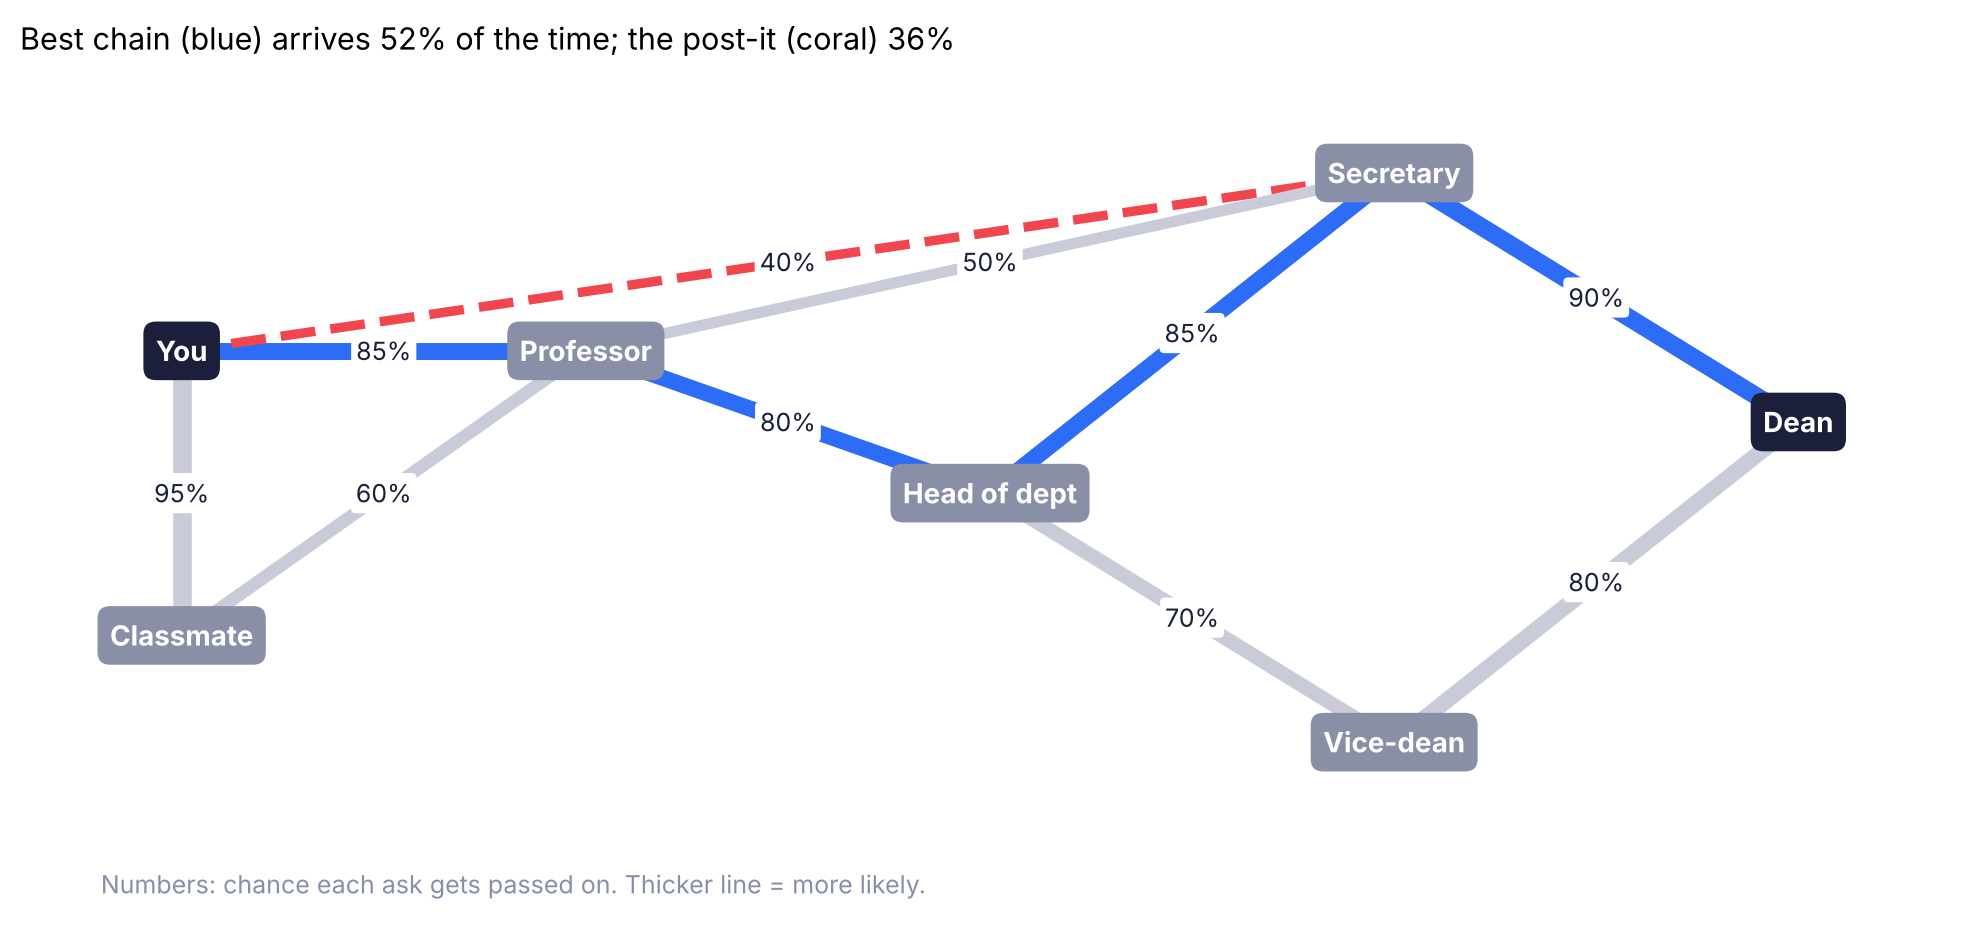

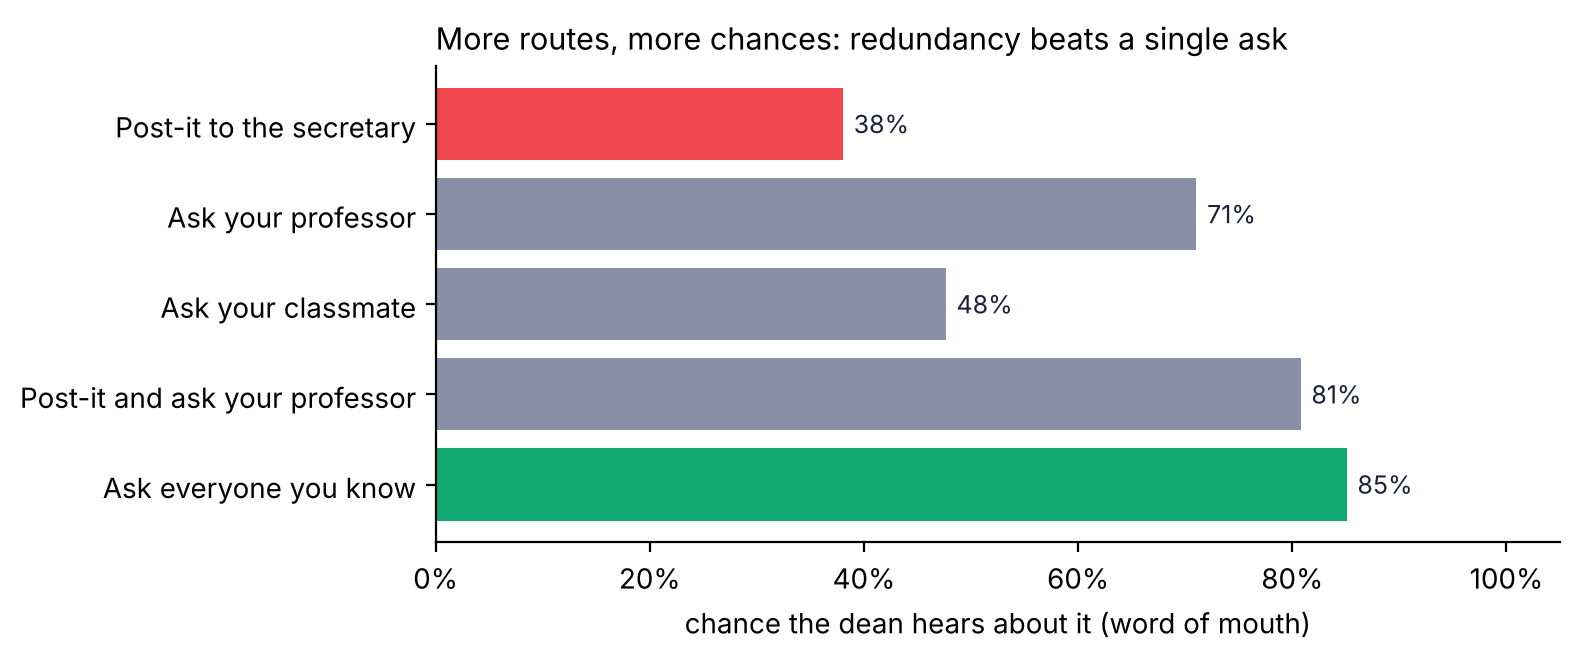

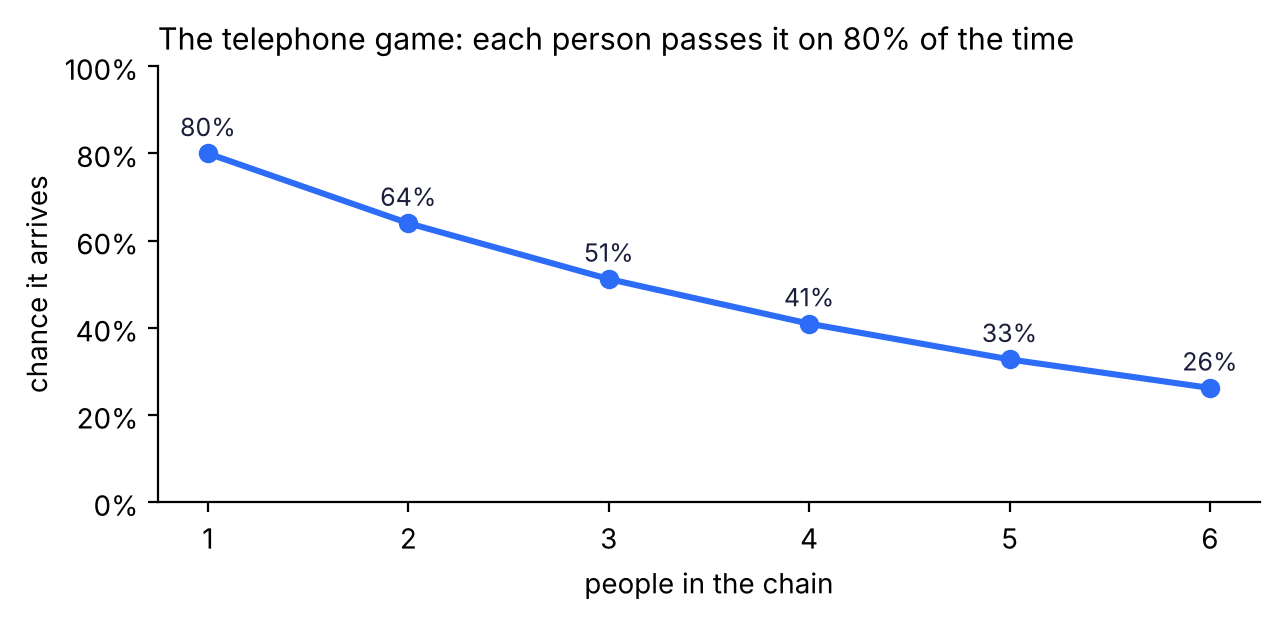

In [7]:
G = build()

print("1. One chosen route (multiply the probabilities):")
for r, p in all_routes(G):
    print(f"   {p:5.0%}  {' -> '.join(r)}")
best = most_reliable_route(G)
print(f"   Dijkstra on -log(p) picks: {' -> '.join(best)} ({route_probability(G, best):.0%})")

print("\n2. Word of mouth (everyone who hears passes it on):")
results = {name: chance_dean_hears(G, asks) for name, asks in STRATEGIES.items()}
for name, p in results.items():
    print(f"   {p:5.0%}  {name}")

print("\n3. The telephone game (each person passes it on 80% of the time):")
print("   " + ", ".join(f"{k} {'person' if k == 1 else 'people'}: {v:.0%}" for k, v in chain_decay()))

draw_network(G, best, path="dean_fig1_routes.png")
draw_strategies(results, path="dean_fig2_strategies.png")
draw_decay(path="dean_fig3_telephone.png")
print("\nSaved dean_fig1_routes.png, dean_fig2_strategies.png, dean_fig3_telephone.png")